<a href="https://colab.research.google.com/github/09StevenG/2022-ii-tutorial-git-repo-ejemplo/blob/main/Semana_06_practica_datos_clim%C3%A1ticos_y_caracterizaci%C3%B3n_de_la_cuenca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#paso 0 definir configuración y librerias
import math, json #calculos matemáticos
import numpy as np #arreglos de numpy (los rasters son np arrays en python)
import pandas as pd #manejo de datos (csv)
import geopandas as gpd #manejo de geometrias (leer la cuenca que ya delimitamos tarea 3 / sem 05)
import rasterio #manejo de rasters
import folium #visualización de mapas
import matplotlib.pyplot as plt #graficos
from rasterio.mask import mask #recorte de rasters por máscara
from shapely.geometry import Point #publicar puntos en mapa
from rasterio.plot import show #para vista previa de rasters


BASE = "https://raw.githubusercontent.com/navilaufm/geodata/main/catie"

pd.set_option("display.max_rows", 20)
print("listo")

listo


In [ ]:
#leer la cuenca
cuenca = gpd.read_file(BASE + "/catie_cuenca_nicoya.geojson")
red = gpd.read_file(BASE + "/catie_red_nicoya.geojson")
print("CRS      ", cuenca.crs) #ver el sistema de coordenadas
print("rasgos   ", len(cuenca), "polígono(s),", len(red), "tramos de cauce")
cuenca.head()

CRS       EPSG:4326
rasgos    1 polígono(s), 39 tramos de cauce


,geometry
0,"POLYGON ((-85.58208 10.18515, -85.58208 10.184..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

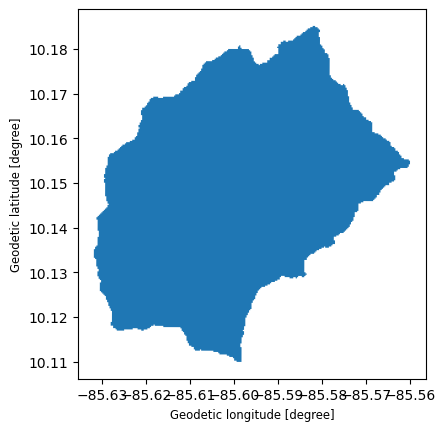

In [ ]:
cuenca.plot() #vista previa de una geometría

In [ ]:
#para hacer mediciones (parte de la caracterización de la cuenca) convertimos a utm
UTM = cuenca.estimate_utm_crs()
print("huso estimado:", UTM.name, "|", UTM.to_string())

huso estimado: WGS 84 / UTM zone 16N | EPSG:32616


In [ ]:
cuenca_m = cuenca.to_crs(UTM) #convirtiendo a utm
red_m = red.to_crs(UTM)

AREA_KM2 = cuenca_m.area.iloc[0] / 1e6
perim_km = cuenca_m.simplify(60).length.iloc[0] / 1000
largo_red = red_m.length.sum() / 1000

print(f"\narea              {AREA_KM2:8.2f} km²")
print(f"perímetro         {perim_km:8.2f} km")
print(f"Gravelius         {0.28 * perim_km * 1000 / math.sqrt(AREA_KM2 * 1e6):8.2f}")
print(f"red de drenaje    {largo_red:8.1f} km en {len(red)} tramos")
print(f"densidad          {largo_red / AREA_KM2:8.2f} km/km²")


area                 37.30 km²
perímetro            27.86 km
Gravelius             1.28
red de drenaje        33.5 km en 39 tramos
densidad              0.90 km/km²


In [ ]:
#veamos en un mapa primero determinamos el centroide. Es el punto mediano/centrico de la cuenca
cen = cuenca.geometry.iloc[0].centroid ##centroid, todos sabemos que es el centroide ?
LAT_C, LON_C = cen.y, cen.x
print(f"centroide: {LAT_C:.5f}, {LON_C:.5f}")



centroide: 10.14810, -85.60002


In [ ]:
m = folium.Map(location=[LAT_C, LON_C], zoom_start=12, tiles=None)
folium.TileLayer("OpenTopoMap", name="Relieve", attr="OpenTopoMap").add_to(m)
##folium.TileLayer("OpenStreetMap", name="Calles").add_to(m)
folium.GeoJson(cuenca, name="Cuenca",
               style_function=lambda f: {"color": "#B85042", "weight": 5,
                                         "fillColor": "#2C5F2D", "fillOpacity": 0.2}).add_to(m)
folium.GeoJson(red, name="Red de drenaje",
               style_function=lambda f: {"color": "#1f5fa8", "weight": 1.5}).add_to(m)
folium.LayerControl().add_to(m)
m

área que cubre el archivo: (1008, 1872) celdas
CRS: EPSG:4326


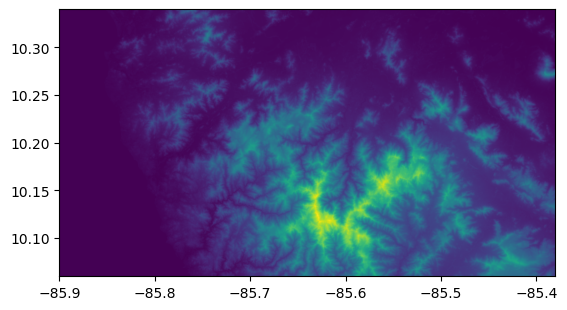


recorte: (272, 260) celdas, de las cuales 39,892 son terreno


In [ ]:
#recortar el raster fuente a la cuenca (mask de rasterio)
with rasterio.open(f"{BASE}/catie_dem_cuenca_nicoya_4326.tif") as src:
    print("área que cubre el archivo:", src.shape, "celdas")
    print("CRS:", src.crs)

    recorte, tr = mask(src, cuenca.geometry, crop=True, nodata=np.nan, filled=True) #recortar
    perfil = src.profile.copy()  #para que tener la misma metadata que el raster original
    show(src) #ver el raster src o original

perfil.update(height=recorte.shape[1], width=recorte.shape[2], #le asignamos dimensiones en la metadata del recorte
              transform=tr, dtype="float32", nodata=np.nan, compress="deflate")
with rasterio.open("dem_cuenca.tif", "w", **perfil) as dst:  #escribimos a disco el nuevo raster recortad
    dst.write(recorte[0].astype("float32"), 1)

z = recorte[0]
print(f"\nrecorte: {z.shape} celdas, de las cuales {int(np.isfinite(z).sum()):,} son terreno")

área que cubre el archivo: (272, 260) celdas
CRS: EPSG:4326


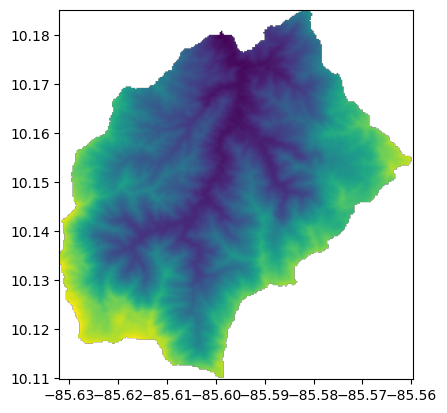

In [ ]:
###ver el recortado
with rasterio.open("dem_cuenca.tif") as src:
    print("área que cubre el archivo:", src.shape, "celdas")
    print("CRS:", src.crs)
    show(src)

elevación            109 – 981 msnm
desnivel             872 m
pendiente media     24.8°


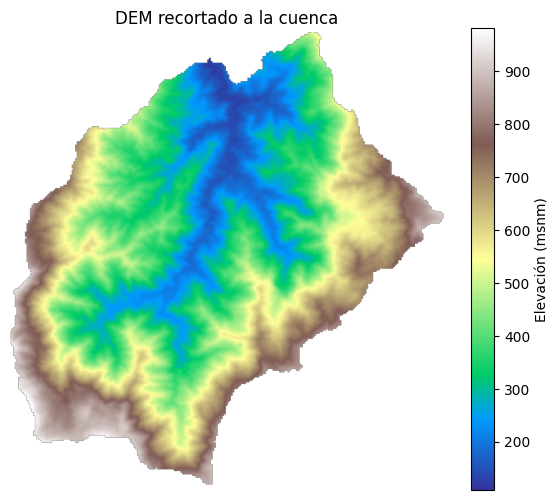

In [ ]:
ELEV_MIN = float(np.nanmin(z))
ELEV_MAX = float(np.nanmax(z))

# pendiente a partir del gradiente, en metros
with rasterio.open("dem_cuenca.tif") as src:
    paso = abs(src.transform.a) * 111320 * math.cos(math.radians(LAT_C))
gy, gx = np.gradient(np.nan_to_num(z, nan=np.nanmean(z)), paso)
pend = np.degrees(np.arctan(np.hypot(gx, gy)))

# El borde del recorte crea un acantilado falso contra el vacío: se excluye
# el anillo exterior antes de promediar.
val = np.isfinite(z)
interior = val.copy()
interior[:-1, :] &= val[1:, :]; interior[1:, :] &= val[:-1, :]
interior[:, :-1] &= val[:, 1:]; interior[:, 1:] &= val[:, :-1]
PENDIENTE = float(np.nanmean(np.where(interior, pend, np.nan)))

print(f"elevación        {ELEV_MIN:7.0f} – {ELEV_MAX:.0f} msnm")
print(f"desnivel         {ELEV_MAX - ELEV_MIN:7.0f} m")
print(f"pendiente media  {PENDIENTE:7.1f}°")

plt.figure(figsize=(7, 6))
plt.imshow(z, cmap="terrain")
plt.colorbar(label="Elevación (msnm)")
plt.title("DEM recortado a la cuenca")
plt.axis("off")
plt.show()

In [ ]:
#probar con la estación mas cercana
EST_LAT, EST_LON, EST_ALT = 10.145556, -85.451944, 130   # IMN, Nicoya Centro https://www.imn.ac.cr/web/imn/mapa#c29tZUhhc2hUaGF0RG9lc250RXhpc3Q
#url https://www.imn.ac.cr/especial/estacionNicoya.html

In [ ]:
def distancia_km(lat1, lon1, lat2, lon2):
    """Distancia sobre la superficie terrestre, en kilómetros. great circle distance calc"""
    R = 6371.0088
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp = math.radians(lat2 - lat1)
    dl = math.radians(lon2 - lon1)
    a = math.sin(dp/2)**2 + math.cos(p1) * math.cos(p2) * math.sin(dl/2)**2
    return 2 * R * math.asin(math.sqrt(a))


d = distancia_km(LAT_C, LON_C, EST_LAT, EST_LON)
elev_media = float(np.nanmean(z)) #calculo de la elevación media promediando cada pixel

print(f"distancia al centroide   {d:6.1f} km")
print(f"altitud de la estación   {EST_ALT:6.0f} msnm")
print(f"elevación media de la cuenca {elev_media:6.0f} msnm")
print(f"diferencia de altitud    {EST_ALT - elev_media:6.0f} m")

distancia al centroide     16.2 km
altitud de la estación      130 msnm
elevación media de la cuenca    471 msnm
diferencia de altitud      -341 m


In [ ]:
def leer_serie(fuente, lat=None, lon=None):
    """Devuelve una serie mensual de precipitación en mm, indexada por fecha.

    La única parte del notebook que sabe de dónde vienen los datos.
    """
    if fuente == "chirps":
        df = pd.read_csv(f"{BASE}/catie_precip_mensual_nicoya_cuenca.csv") ##el repo con los datos que conseguimos de chirps
        df["fecha"] = pd.to_datetime(df["fecha"])
        return df.set_index("fecha")

    if fuente == "reanalisis":
        return _pedir_open_meteo(lat, lon)

    if fuente == "estacion":
        raise NotImplementedError(
            "Aquí iría la lectura del CSV de una estación propia. "
            "Para esta cuenca no hay serie histórica disponible.")

    raise ValueError(f"fuente desconocida: {fuente}")


serie = leer_serie("chirps")
print(f"{len(serie)} meses, de {serie.index.min():%Y-%m} a {serie.index.max():%Y-%m}")
serie

549 meses, de 1981-01 a 2026-09


,precip_mm,vecindad_media_mm,vecindad_min_mm,vecindad_max_mm,preliminar
fecha,,,,,
1981-01-01,1.2,1.2,1.1,1.3,0
1981-02-01,1.5,0.8,0.2,1.5,0
1981-03-01,10.5,12.2,7.9,17.0,0
1981-04-01,72.2,62.3,54.5,74.4,0
1981-05-01,483.9,448.6,396.6,499.2,0
...,...,...,...,...,...
2026-05-01,129.3,116.5,103.9,129.3,0
2026-06-01,292.5,279.0,271.2,292.5,0
2026-07-01,176.4,166.8,150.0,184.9,0


In [ ]:
print("huecos por columna:")
print(serie.isna().sum())
print(f"\nmeses preliminares: {int(serie['preliminar'].sum())}")

p = serie["precip_mm"]
print(f"\nmínimo mensual   {p.min():7.1f} mm")
print(f"máximo mensual   {p.max():7.1f} mm  ({p.idxmax():%Y-%m})")
print(f"media mensual    {p.mean():7.1f} mm")

huecos por columna:
precip_mm            0
vecindad_media_mm    0
vecindad_min_mm      0
vecindad_max_mm      0
preliminar           0
dtype: int64

meses preliminares: 1

mínimo mensual       0.0 mm
máximo mensual    1016.2 mm  (2024-11)
media mensual      199.7 mm


In [ ]:
base = p["1991":"2020"] #slice recortar la serie a un rangp.
normal = base.groupby(base.index.month).mean() #promedio agrupado por mes
normal.index = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

LAMINA_ANUAL = normal.sum() #suma de los promedios

print(normal.round(1).to_string())
print(f"\nANUAL  {LAMINA_ANUAL:.0f} mm")

seca = normal[["Dic", "Ene", "Feb", "Mar"]].sum()
print(f"\nDiciembre a marzo: {seca:.1f} mm = {seca / LAMINA_ANUAL * 100:.1f} % del año")

Ene      6.2
Feb      7.5
Mar      8.2
Abr     43.5
May    275.3
Jun    317.4
Jul    268.6
Ago    361.8
Sep    419.6
Oct    477.7
Nov    190.1
Dic     19.0

ANUAL  2395 mm

Diciembre a marzo: 40.9 mm = 1.7 % del año


In [ ]:
#determinación de la canícula en esta cuenca basado en su historial de lluvia
jun, jul, ago = normal["Jun"], normal["Jul"], normal["Ago"]
print(f"Jun {jun:.1f} mm  ->  Jul {jul:.1f} mm  ->  Ago {ago:.1f} mm")
print(f"Julio cae {(1 - jul/ago) * 100:.0f} % respecto a agosto")

Jun 317.4 mm  ->  Jul 268.6 mm  ->  Ago 361.8 mm
Julio cae 26 % respecto a agosto


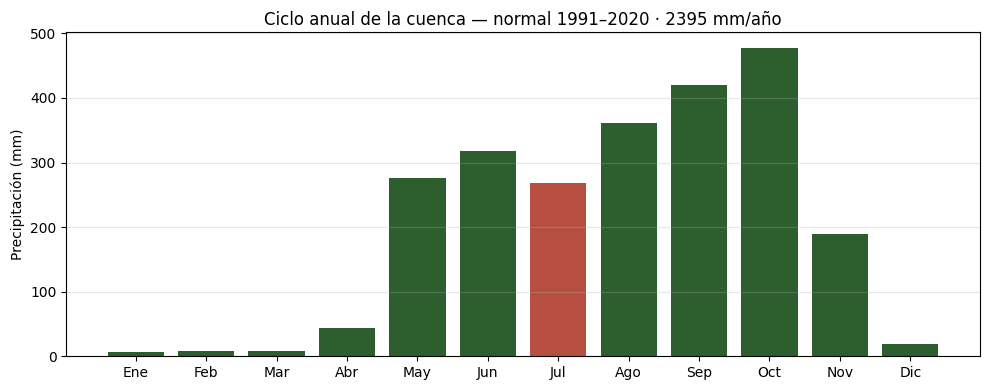

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
col = ["#2C5F2D"] * 12
col[6] = "#B85042"                      # julio, el veranillo solo le cambio el color a esta columna
ax.bar(normal.index, normal.values, color=col)
ax.set_ylabel("Precipitación (mm)")
ax.set_title(f"Ciclo anual de la cuenca — normal 1991–2020 · {LAMINA_ANUAL:.0f} mm/año")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

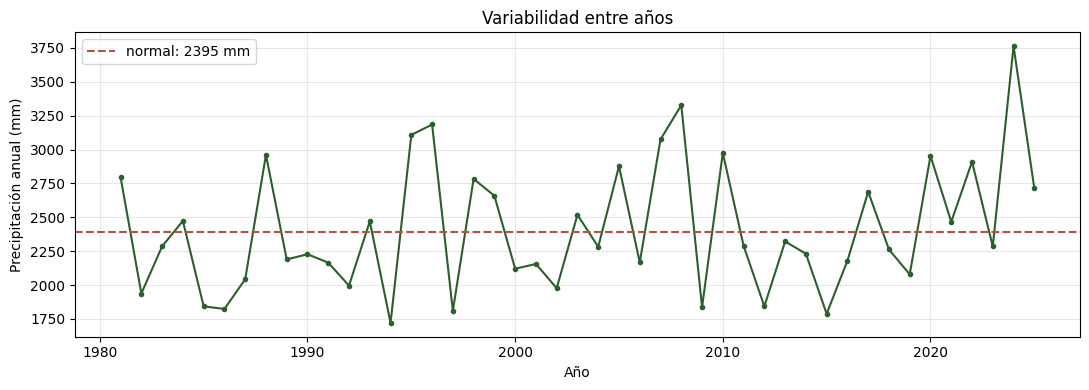

más lluvioso  2024  3764 mm
más seco      1994  1721 mm
razón entre extremos: 2.19


In [ ]:
anual = p.resample("YE").sum()
anual = anual[anual.index.year <= 2025]          # el año en curso está incompleto

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(anual.index.year, anual.values, color="#2C5F2D", marker="o", markersize=3)
ax.axhline(LAMINA_ANUAL, color="#B85042", linestyle="--",
           label=f"normal: {LAMINA_ANUAL:.0f} mm")
ax.set_ylabel("Precipitación anual (mm)"); ax.set_xlabel("Año")
ax.set_title("Variabilidad entre años")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"más lluvioso  {anual.idxmax():%Y}  {anual.max():.0f} mm")
print(f"más seco      {anual.idxmin():%Y}  {anual.min():.0f} mm")
print(f"razón entre extremos: {anual.max()/anual.min():.2f}")

In [ ]:
#contrastar con otra fuente, la fuente de reanalisis de open-meteo ERA5 nos da datos diarios,
def _pedir_open_meteo(lat, lon, inicio="1991-01-01", fin="2020-12-31"):
    """Serie mensual de precipitación del reanálisis, vía Open-Meteo."""
    url = ("https://archive-api.open-meteo.com/v1/archive"
           f"?latitude={lat}&longitude={lon}"
           f"&start_date={inicio}&end_date={fin}"
           "&daily=precipitation_sum&timezone=auto")
    j = pd.read_json(url, typ="series")
    d = pd.DataFrame({"fecha": pd.to_datetime(j["daily"]["time"]),
                      "precip_mm": j["daily"]["precipitation_sum"]})
    mensual = d.set_index("fecha")["precip_mm"].resample("MS").sum() #se agrupan por mes para hacerlos comparables con chirps
    print("Fuente: ", url)
    return pd.DataFrame({"precip_mm": mensual}), j


rea, meta = _pedir_open_meteo(LAT_C, LON_C)   # pide ~30 años: tarda unos segundos

print(f"se pidió        {LAT_C:.5f}, {LON_C:.5f}")
print(f"el modelo usó   {meta['latitude']:.5f}, {meta['longitude']:.5f}")
print(f"separación      {distancia_km(LAT_C, LON_C, meta['latitude'], meta['longitude']):.1f} km")
print(f"\nelevación del modelo en esa celda: {meta['elevation']:.0f} m")
print(f"elevación real de la cuenca:       {ELEV_MIN:.0f} – {ELEV_MAX:.0f} m")


Fuente:  https://archive-api.open-meteo.com/v1/archive?latitude=10.148097671520091&longitude=-85.60001904819491&start_date=1991-01-01&end_date=2020-12-31&daily=precipitation_sum&timezone=auto
se pidió        10.14810, -85.60002
el modelo usó   10.15817, -85.57895
separación      2.6 km

elevación del modelo en esa celda: 216 m
elevación real de la cuenca:       109 – 981 m


     CHIRPS  Reanálisis  diferencia    % 
Ene     6.2         7.1         0.9  15.0
Feb     7.5         8.7         1.2  16.0
Mar     8.2         8.1        -0.1  -1.0
Abr    43.5        43.2        -0.3  -1.0
May   275.3       253.9       -21.4  -8.0
Jun   317.4       317.1        -0.3  -0.0
Jul   268.6       230.6       -38.0 -14.0
Ago   361.8       264.8       -97.0 -27.0
Sep   419.6       352.2       -67.4 -16.0
Oct   477.7       385.7       -92.0 -19.0
Nov   190.1       154.4       -35.7 -19.0
Dic    19.0        22.5         3.5  18.0

anual CHIRPS      2395 mm
anual reanálisis  2048 mm
diferencia        -347 mm (-14 %)


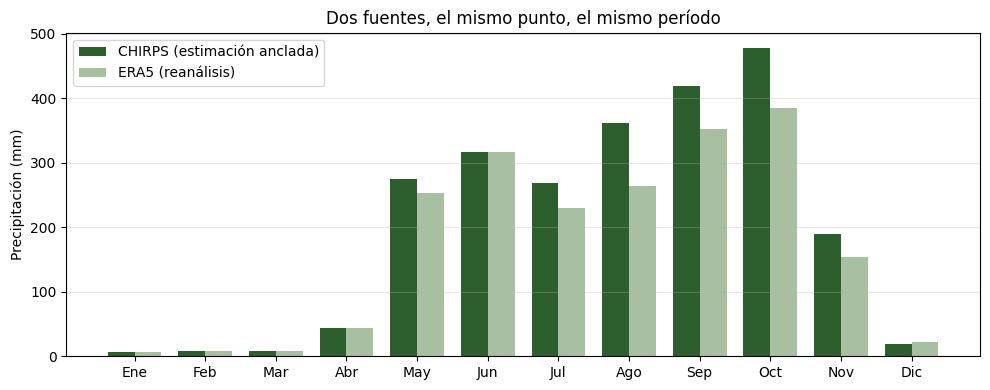

In [ ]:
n_rea = rea["precip_mm"].groupby(rea.index.month).mean()
n_rea.index = normal.index

comp = pd.DataFrame({"CHIRPS": normal.round(1),
                     "Reanálisis": n_rea.round(1)})
comp["diferencia"] = (comp["Reanálisis"] - comp["CHIRPS"]).round(1)
comp["% "] = (comp["diferencia"] / comp["CHIRPS"] * 100).round(0)
print(comp.to_string())
print(f"\nanual CHIRPS      {normal.sum():.0f} mm")
print(f"anual reanálisis  {n_rea.sum():.0f} mm")
print(f"diferencia        {n_rea.sum() - normal.sum():+.0f} mm ({(n_rea.sum()/normal.sum()-1)*100:+.0f} %)")

fig, ax = plt.subplots(figsize=(10, 4))
w = 0.38
xs = np.arange(12)
ax.bar(xs - w/2, normal.values, w, label="CHIRPS (estimación anclada)", color="#2C5F2D")
ax.bar(xs + w/2, n_rea.values, w, label="ERA5 (reanálisis)", color="#A9BFA2")
ax.set_xticks(xs); ax.set_xticklabels(normal.index)
ax.set_ylabel("Precipitación (mm)")
ax.set_title("Dos fuentes, el mismo punto, el mismo período")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
#saber que al final aunque tenemos una lamina (mm/mes mm/año) vamos a calcular volumen
VOLUMEN_MM3 = (LAMINA_ANUAL / 1000) * (AREA_KM2 * 1e6) / 1e6

print(f"lámina media anual   {LAMINA_ANUAL:8.0f} mm")
print(f"área de la cuenca    {AREA_KM2:8.2f} km²")
print(f"volumen medio anual  {VOLUMEN_MM3:8.1f} millones de m³")

anual_mm3 = anual / 1000 * AREA_KM2 * 1e6 / 1e6
print(f"\nen el año más húmedo  {anual_mm3.max():.1f} millones de m³")
print(f"en el año más seco    {anual_mm3.min():.1f} millones de m³")

lámina media anual       2395 mm
área de la cuenca       37.30 km²
volumen medio anual      89.3 millones de m³

en el año más húmedo  140.4 millones de m³
en el año más seco    64.2 millones de m³


In [ ]:
# Siete días de una estación. Tres sin dato.
ejemplo = pd.Series([12.0, np.nan, np.nan, 8.5, 0.0, np.nan, 3.2])

print("días con dato        :", ejemplo.count(), "de", len(ejemplo))
print()
print("suma ignorando datos faltantes:", ejemplo.sum(), " <- parece un total, le faltan 3 días")
print("suma exigiendo los 7 :", ejemplo.sum(min_count=7), " <- avisa que no se puede")
print()
print("promedio de lo medido:", round(ejemplo.mean(), 2), "mm/día")
print("promedio con ceros   :", round(ejemplo.fillna(0).mean(), 2),
      "mm/día  <- inventa tres días secos")

días con dato        : 4 de 7

suma ignorando datos faltantes: 23.7  <- parece un total, le faltan 3 días
suma exigiendo los 7 : nan  <- avisa que no se puede

promedio de lo medido: 5.92 mm/día
promedio con ceros   : 3.39 mm/día  <- inventa tres días secos


In [ ]:
# Así se reporta un acumulado con su respaldo
resumen = p.resample("YE").agg(["sum", "count"])
resumen.columns = ["mm", "meses_con_dato"]
print(resumen.to_string())

                mm  meses_con_dato
fecha                             
1981-12-31  2795.9              12
1982-12-31  1937.7              12
1983-12-31  2285.9              12
1984-12-31  2473.4              12
1985-12-31  1843.2              12
1986-12-31  1823.4              12
1987-12-31  2043.1              12
1988-12-31  2961.1              12
1989-12-31  2189.2              12
1990-12-31  2227.6              12
1991-12-31  2165.5              12
1992-12-31  1995.9              12
1993-12-31  2470.3              12
1994-12-31  1720.9              12
1995-12-31  3108.5              12
1996-12-31  3185.3              12
1997-12-31  1809.3              12
1998-12-31  2784.1              12
1999-12-31  2659.0              12
2000-12-31  2120.6              12
2001-12-31  2155.9              12
2002-12-31  1977.0              12
2003-12-31  2518.8              12
2004-12-31  2282.2              12
2005-12-31  2877.2              12
2006-12-31  2167.2              12
2007-12-31  3075.2  

In [ ]:
#todo lo calculado lo guardamos, descargamos
cuenca.to_file("cuenca.geojson", driver="GeoJSON")
red.to_file("red_drenaje.geojson", driver="GeoJSON")
serie.to_csv("precip_mensual.csv")
normal.round(1).to_csv("normal_mensual.csv", header=["precip_mm"])

ficha = {
    "nombre": "Micro cuenca parque Nacional Diriá ",
    "area_km2": round(AREA_KM2, 2),
    "elevacion_min_msnm": round(ELEV_MIN),
    "elevacion_max_msnm": round(ELEV_MAX),
    "pendiente_media_grados": round(PENDIENTE, 1),
    "lamina_anual_mm": round(LAMINA_ANUAL),
    "volumen_anual_millones_m3": round(VOLUMEN_MM3, 1),
    "fuente_precipitacion": "CHIRPS v3 (Climate Hazards Center, UC Santa Barbara)",
    "nivel_del_dato": "estimacion anclada en observaciones",
    "periodo_normal": "1991-2020",
    "por_que_esta_fuente": (
        "No hay estacion con serie historica cerca de la cuenca. "
        "La mas proxima esta a 16 km y 370 m por debajo de la elevacion media, "
        "y solo publica datos en tiempo real sin control de calidad."),
}
with open("ficha_cuenca.json", "w", encoding="utf-8") as f:
    json.dump(ficha, f, ensure_ascii=False, indent=2)

print(json.dumps(ficha, ensure_ascii=False, indent=2))

{
  "nombre": "Micro cuenca parque Nacional Diriá ",
  "area_km2": 37.3,
  "elevacion_min_msnm": 109,
  "elevacion_max_msnm": 981,
  "pendiente_media_grados": 24.8,
  "lamina_anual_mm": 2395,
  "volumen_anual_millones_m3": 89.3,
  "fuente_precipitacion": "CHIRPS v3 (Climate Hazards Center, UC Santa Barbara)",
  "nivel_del_dato": "estimacion anclada en observaciones",
  "periodo_normal": "1991-2020",
  "por_que_esta_fuente": "No hay estacion con serie historica cerca de la cuenca. La mas proxima esta a 16 km y 370 m por debajo de la elevacion media, y solo publica datos en tiempo real sin control de calidad."
}


In [ ]:
from google.colab import files
for f in ["cuenca.geojson", "red_drenaje.geojson", "dem_cuenca.tif",
          "precip_mensual.csv", "normal_mensual.csv", "ficha_cuenca.json"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>